In [1]:
"""
Figure S6: Quasi-Decadal Cycle Extraction (SSA) and Residual Regime-Shift Test
================================================================================

Extracts the quasi-decadal (~8-10 yr) oscillatory component from the OSISAF
annual maximum sea-ice extent (SIE) timeseries via Singular Spectrum Analysis
(SSA), formally tests its significance against a red-noise (AR(1)) null via
Monte Carlo SSA (Allen & Smith, 1996), subtracts it, and re-runs the paper's
standard SPLIT_YEAR=2015 breakpoint statistics (piecewise regression,
bootstrap CI, Yue-Wang MK test) on the residual.

Purpose
-------
Directly tests whether the post-2015 regime-shift signal (Figures 4-6)
survives once the quasi-decadal internal-variability mode -- independently
identified via SSA (this notebook) and via a fixed 9-16yr Butterworth
bandpass filter (Xu et al. 2026's own method, used here as a cross-check) --
is removed from the record.

Data
----
Reuses the cached annual-maximum SIE series already produced by
figure_01_SIE_timeseries_and_SIC_spatial_trends.ipynb:
    ./outputs/processed_data/figure_01/annual_max_sie_dates.csv
      columns: year, pan_arctic_max_sie, pan_arctic_max_date,
               greenland_sea_max_sie, greenland_sea_max_date
No reprocessing from raw OSISAF files is needed for this notebook; if that
cache doesn't exist yet, run figure_01 once first (REPROCESS=True there).

Method
------
  1. SSA: trajectory (lag-embedded) matrix -> SVD -> eigen-triples -> RCs
  2. Grouping diagnostics: w-correlation matrix + FFT of each RC
  3. Monte Carlo SSA: AR(1) surrogate ensemble -> significance of eigenvalues
     at the ~8-10 yr frequency band, cf. Allen & Smith (1996)
  4. Reconstruct + subtract the significant QD eigen-triple pair -> residual
  5. Cross-check: independently extract QD via Xu et al.'s fixed 9-16yr
     Butterworth bandpass, subtract, compare residual conclusions
  6. Re-run SPLIT_YEAR=2015 breakpoint statistics on: original, SSA-residual,
     bandpass-residual
  7. Robustness: repeat SSA extraction across several window lengths L

Implementation note: SSA and Monte Carlo SSA are implemented here in plain
numpy/scipy rather than a third-party SSA package, consistent with the
project's existing dependency set (no pymssa/pyts etc. added).

Outputs
-------
  Figure:         ./outputs/figures/figure_s06_QD_SSA_extraction.png
  Processed data: ./outputs/processed_data/figure_s06/
  Methodology:    ./outputs/methods/figure_s06_methodology.md
  Log:            ./outputs/logs/figure_s06.log

Version:       0.1.0 (draft)
Last Modified: 2026-08-19
Author:        Chris Barrell
"""

import os
import sys
import logging
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, signal
import pymannkendall as mk

warnings.filterwarnings("ignore")

sys.path.append('..')
try:
    from utils.logger import get_logger
    logger = get_logger(__name__, config_path='../config.yaml')
except Exception:
    logger = logging.getLogger(__name__)
    logging.basicConfig(level=logging.INFO)

# ============================================================================
# CONFIGURATION
# ============================================================================

# --- Source: reuse figure_01's cached annual-max SIE table (no reprocessing) ---
FIGURE01_CSV = './outputs/processed_data/figure_01/annual_max_sie_dates.csv'

# Which series to analyse. 'greenland_sea_max_sie' matches the SSA figure
# already produced (Greenland Sea panel); 'pan_arctic_max_sie' included for
# the companion pan-Arctic panel.
SERIES_COLS = {
    'greenland_sea': 'greenland_sea_max_sie',
    'pan_arctic':    'pan_arctic_max_sie',
}

START_YEAR = 1979          # matches figure_01's START_YEAR
SPLIT_YEAR = 2015          # matches project-wide breakpoint convention

# --- SSA configuration ---
L_DEFAULT   = 18           # window length; ~1.8-2.25 cycles of an 8-10yr QD signal
L_SENSITIVITY = [12, 15, 18, 20]   # robustness sweep (Step 7)
QD_PERIOD_RANGE = (8, 12)  # yr; band used to identify the QD eigen-triple pair

# --- Monte Carlo SSA configuration ---
MC_N_SURROGATES = 1000
MC_CONFIDENCE   = 0.95

# --- Bandpass cross-check (Xu et al. 2026 method) ---
BANDPASS_LOW_YR  = 9
BANDPASS_HIGH_YR = 16

# --- Breakpoint / bootstrap conventions (project-wide) ---
N_BOOTSTRAP = 1000
CI_LEVEL    = 0.95

# --- Output dirs ---
OUTPUT_DIR    = './outputs/figures/'
PROCESSED_DIR = './outputs/processed_data/figure_s06/'
METHODS_DIR   = './outputs/methods/'
LOG_DIR       = './outputs/logs/'
for d in [OUTPUT_DIR, PROCESSED_DIR, METHODS_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

log_path = os.path.join(LOG_DIR, 'figure_s06.log')
fh = logging.FileHandler(log_path, mode='w')
fh.setLevel(logging.INFO)
fh.setFormatter(logging.Formatter('%(asctime)s %(levelname)s %(message)s'))
logger.addHandler(fh)

FIG_DPI = 600


## Section 1 - Load the cached OSISAF annual-max SIE series (figure_01 output)

In [2]:
if not os.path.exists(FIGURE01_CSV):
    raise FileNotFoundError(
        f"{FIGURE01_CSV} not found. Run figure_01_SIE_timeseries_and_SIC_"
        f"spatial_trends.ipynb once first (REPROCESS=True there) to "
        f"generate the cached annual-maximum SIE table."
    )

date_table = pd.read_csv(FIGURE01_CSV, parse_dates=['pan_arctic_max_date',
                                                      'greenland_sea_max_date'])
date_table['year'] = date_table['year'].astype(int)
date_table = date_table[date_table['year'] >= START_YEAR].sort_values('year').reset_index(drop=True)

logger.info(f"Loaded {len(date_table)} years ({date_table['year'].min()}-"
            f"{date_table['year'].max()}) from {FIGURE01_CSV}")

series_dict = {
    name: date_table.set_index('year')[col].astype(float)
    for name, col in SERIES_COLS.items()
}


INFO:__main__:Loaded 48 years (1979-2026) from ./outputs/processed_data/figure_01/annual_max_sie_dates.csv


## Section 2 - SSA: trajectory matrix, SVD, reconstructed components (RCs)

In [3]:
def ssa_decompose(y, L):
    """Basic (Broomhead-King) SSA via SVD of the trajectory matrix.

    Parameters
    ----------
    y : 1-D array, assumed regularly sampled, no NaNs
    L : window length (embedding dimension)

    Returns
    -------
    eigenvalues : (L,) array, descending
    eigenvectors : (L, L) array, columns are eigenvectors (U from SVD)
    RCs : (L, N) array, reconstructed component for each eigen-triple,
          diagonal-averaged back to the original series length N
    """
    N = len(y)
    K = N - L + 1
    if K < L:
        raise ValueError(f"Window length L={L} too large for series of length N={N} "
                          f"(need L <= N/2 as a rule of thumb; K={K} < L={L})")

    # Trajectory (Hankel) matrix
    X = np.column_stack([y[i:i + L] for i in range(K)])  # shape (L, K)

    U, S, Vt = np.linalg.svd(X, full_matrices=False)
    d = np.sum(S > 1e-10)  # rank

    eigenvalues = S[:d] ** 2
    eigenvectors = U[:, :d]

    RCs = np.zeros((d, N))
    for k in range(d):
        Xk = S[k] * np.outer(U[:, k], Vt[k, :])  # rank-1 elementary matrix, shape (L, K)
        # Diagonal averaging (Hankelisation) back to a length-N series
        rc = np.zeros(N)
        counts = np.zeros(N)
        for i in range(L):
            for j in range(K):
                rc[i + j] += Xk[i, j]
                counts[i + j] += 1
        RCs[k] = rc / counts

    return eigenvalues, eigenvectors, RCs


def w_correlation(RCs, L):
    """Weighted (w-)correlation matrix between reconstructed components.
    Low off-diagonal |w-corr| between two RCs indicates they are cleanly
    separable; high |w-corr| is a warning that the grouping is ambiguous.
    """
    N = RCs.shape[1]
    K = N - L + 1
    Lstar, Kstar = min(L, K), max(L, K)
    w = np.array([min(i + 1, Lstar, N - i) for i in range(N)])

    def wnorm(x):
        return np.sqrt(np.sum(w * x ** 2))

    d = RCs.shape[0]
    Wcorr = np.zeros((d, d))
    norms = np.array([wnorm(RCs[k]) for k in range(d)])
    for i in range(d):
        for j in range(d):
            Wcorr[i, j] = np.sum(w * RCs[i] * RCs[j]) / (norms[i] * norms[j])
    return Wcorr


def dominant_period_years(rc, dt=1.0):
    """Dominant period (years) of a single RC via its power spectrum."""
    n = len(rc)
    freqs = np.fft.rfftfreq(n, d=dt)
    power = np.abs(np.fft.rfft(rc - rc.mean())) ** 2
    if len(freqs) < 2:
        return np.nan
    peak_idx = np.argmax(power[1:]) + 1  # skip zero frequency
    return 1.0 / freqs[peak_idx] if freqs[peak_idx] > 0 else np.nan


## Section 3 - Monte Carlo SSA: AR(1) surrogate significance test (Allen & Smith, 1996)

In [4]:
def fit_ar1(y):
    """Fit lag-1 autocorrelation coefficient and innovation std to a
    detrended series (simple AR(1) null model)."""
    y_detrend = signal.detrend(y)
    phi = np.corrcoef(y_detrend[:-1], y_detrend[1:])[0, 1]
    resid_std = np.std(y_detrend[1:] - phi * y_detrend[:-1])
    return phi, resid_std, y.mean(), y.std()


def generate_ar1_surrogate(n, phi, resid_std, mean, target_std, rng):
    """Generate one AR(1) red-noise surrogate matched to the original
    series' mean and variance."""
    e = rng.normal(0, resid_std, size=n)
    x = np.zeros(n)
    x[0] = e[0]
    for t in range(1, n):
        x[t] = phi * x[t - 1] + e[t]
    x = x / x.std() * target_std  # rescale to match original variance
    return x + mean


def monte_carlo_ssa_significance(y, L, n_surrogates=MC_N_SURROGATES,
                                  confidence=MC_CONFIDENCE, seed=42):
    """Monte Carlo SSA (Allen & Smith, 1996): projects each AR(1) surrogate
    onto the ORIGINAL series' eigenvectors (not re-decomposing each
    surrogate), giving a null distribution of eigenvalues per eigen-triple
    against which the true eigenvalues are tested.
    """
    eigenvalues, eigenvectors, RCs = ssa_decompose(y, L)
    N = len(y)
    K = N - L + 1
    phi, resid_std, mean, target_std = fit_ar1(y)

    rng = np.random.default_rng(seed)
    d = len(eigenvalues)
    surrogate_eigs = np.zeros((n_surrogates, d))

    for s in range(n_surrogates):
        y_surr = generate_ar1_surrogate(N, phi, resid_std, mean, target_std, rng)
        X_surr = np.column_stack([y_surr[i:i + L] for i in range(K)])
        # Project surrogate trajectory matrix onto the ORIGINAL eigenvectors
        proj = eigenvectors.T @ X_surr
        surrogate_eigs[s] = np.sum(proj ** 2, axis=1) / K

    lower = np.percentile(surrogate_eigs, (1 - confidence) / 2 * 100, axis=0)
    upper = np.percentile(surrogate_eigs, (1 + confidence) / 2 * 100, axis=0)
    significant = eigenvalues > upper

    return pd.DataFrame({
        'eigen_triple':  np.arange(d),
        'eigenvalue':    eigenvalues,
        'ar1_null_lower': lower,
        'ar1_null_upper': upper,
        'significant':   significant,
    })


## Section 4 - Identify and subtract the QD eigen-triple pair

In [5]:
def extract_qd_residual(y, years, L, label, period_range=QD_PERIOD_RANGE):
    """Run SSA + Monte Carlo SSA, identify the significant eigen-triple PAIR
    whose dominant period falls in period_range, subtract it, and return
    the residual plus diagnostics."""
    logger.info(f"[{label}] SSA decomposition, L={L}")
    eigenvalues, eigenvectors, RCs = ssa_decompose(y, L)
    mc_result = monte_carlo_ssa_significance(y, L)

    periods = np.array([dominant_period_years(RCs[k]) for k in range(RCs.shape[0])])
    mc_result['dominant_period_yr'] = periods

    # Candidate QD components: significant AND period in range
    candidates = mc_result[
        mc_result['significant'] &
        (mc_result['dominant_period_yr'] >= period_range[0]) &
        (mc_result['dominant_period_yr'] <= period_range[1])
    ]

    if len(candidates) < 2:
        logger.warning(f"[{label}] Fewer than 2 significant eigen-triples found "
                        f"in the {period_range} yr band (found {len(candidates)}). "
                        f"QD pair not cleanly identified — inspect mc_result manually "
                        f"and/or try a different L.")
        qd_indices = candidates['eigen_triple'].tolist()
    else:
        # Take the pair with the closest matching eigenvalues (true SSA
        # oscillatory pairs have near-equal eigenvalues)
        cand = candidates.sort_values('eigenvalue', ascending=False).reset_index(drop=True)
        qd_indices = cand['eigen_triple'].iloc[:2].tolist()

    logger.info(f"[{label}] QD eigen-triple indices: {qd_indices} "
                f"(periods: {periods[qd_indices] if qd_indices else 'n/a'})")

    RC_QD = RCs[qd_indices].sum(axis=0) if qd_indices else np.zeros_like(y)
    residual = y - RC_QD

    # w-correlation check: how cleanly separated is the QD pair from the rest?
    Wcorr = w_correlation(RCs, L)

    return {
        'label': label, 'L': L, 'qd_indices': qd_indices,
        'RC_QD': RC_QD, 'residual': residual, 'mc_result': mc_result,
        'Wcorr': Wcorr, 'RCs': RCs, 'years': years,
    }


ssa_results = {}
for name, series in series_dict.items():
    y = series.values
    years = series.index.values
    ssa_results[name] = extract_qd_residual(y, years, L_DEFAULT, name)


INFO:__main__:[greenland_sea] SSA decomposition, L=18
INFO:__main__:[greenland_sea] QD eigen-triple indices: [1, 4] (periods: [8. 8.])
INFO:__main__:[pan_arctic] SSA decomposition, L=18
INFO:__main__:[pan_arctic] QD eigen-triple indices: [1, 2] (periods: [12. 12.])


## Section 5 - Cross-check: fixed 9-16yr Butterworth bandpass (Xu et al. 2026 method)

In [6]:
def butterworth_bandpass_extract(y, low_yr=BANDPASS_LOW_YR, high_yr=BANDPASS_HIGH_YR,
                                  fs=1.0, order=4):
    """9-16yr Butterworth bandpass, matching Xu et al. (2026)'s own QD
    extraction method exactly, as an independent cross-check against SSA."""
    nyq = 0.5 * fs
    low_freq  = 1.0 / high_yr / nyq
    high_freq = 1.0 / low_yr / nyq
    b, a = signal.butter(order, [low_freq, high_freq], btype='band')
    # Reflect-pad to reduce edge effects on a short series
    pad = min(len(y) - 1, 3 * order * 2)
    y_padded = np.concatenate([y[pad:0:-1], y, y[-2:-pad - 2:-1]])
    filtered = signal.filtfilt(b, a, y_padded)
    return filtered[pad:pad + len(y)]


bandpass_results = {}
for name, series in series_dict.items():
    y = series.values
    qd_bandpass = butterworth_bandpass_extract(y)
    residual_bandpass = y - qd_bandpass
    bandpass_results[name] = {'QD_bandpass': qd_bandpass, 'residual_bandpass': residual_bandpass}
    logger.info(f"[{name}] Bandpass QD variance fraction: "
                f"{np.var(qd_bandpass) / np.var(y):.3f}")


INFO:__main__:[greenland_sea] Bandpass QD variance fraction: 0.040
INFO:__main__:[pan_arctic] Bandpass QD variance fraction: 0.064


## Section 6 - Breakpoint statistics on original vs. SSA-residual vs. bandpass-residual

In [7]:
def bootstrap_trend_ci(x, y, n_bootstrap=N_BOOTSTRAP, confidence_level=CI_LEVEL):
    """Bootstrap CI for a linear trend. (reused from figure_04_PSW_and_AW convention)"""
    mask = ~np.isnan(y)
    x_clean, y_clean = x[mask], y[mask]
    n = len(x_clean)
    trends = []
    for _ in range(n_bootstrap):
        idx = np.random.choice(n, size=n, replace=True)
        p_boot = np.polyfit(x_clean[idx], y_clean[idx], 1)
        trends.append(np.polyval(p_boot, x))
    trends = np.array(trends)
    alpha = 1 - confidence_level
    lower = np.percentile(trends, (alpha / 2) * 100, axis=0)
    upper = np.percentile(trends, (1 - alpha / 2) * 100, axis=0)
    return lower, upper


def run_breakpoint(years, y, split_year=SPLIT_YEAR):
    """Piecewise linear trend + Yue-Wang MK test either side of split_year,
    matching the project-wide SPLIT_YEAR convention (Period 1: year < split;
    Period 2: year >= split)."""
    mask_1 = years < split_year
    mask_2 = years >= split_year
    out = {}
    for label, m in [('period_1', mask_1), ('period_2', mask_2)]:
        yy = y[m]
        xx = years[m].astype(float)
        if np.sum(~np.isnan(yy)) < 8:
            out[label] = None
            continue
        valid = ~np.isnan(yy)
        slope, intercept, *_ = stats.linregress(xx[valid], yy[valid])
        mk_res = mk.yue_wang_modification_test(yy[valid]) if valid.sum() >= 8 else None
        out[label] = {
            'n': int(valid.sum()),
            'slope_per_decade': slope * 10,
            'mk_trend': mk_res.trend if mk_res else None,
            'mk_p': mk_res.p if mk_res else None,
        }
    return out


breakpoint_summary = []
for name, series in series_dict.items():
    years = series.index.values.astype(float)
    y_orig  = series.values
    y_ssa   = ssa_results[name]['residual']
    y_bpf   = bandpass_results[name]['residual_bandpass']

    for tag, y in [('original', y_orig), ('SSA_residual', y_ssa), ('bandpass_residual', y_bpf)]:
        bp = run_breakpoint(years, y)
        for period, res in bp.items():
            if res is None:
                continue
            row = {'series': name, 'extraction': tag, 'period': period}
            row.update(res)
            breakpoint_summary.append(row)

breakpoint_df = pd.DataFrame(breakpoint_summary)
breakpoint_df.to_csv(PROCESSED_DIR + 'breakpoint_comparison.csv', index=False)
logger.info(f"Breakpoint comparison saved: {PROCESSED_DIR}breakpoint_comparison.csv")
breakpoint_df


INFO:__main__:Breakpoint comparison saved: ./outputs/processed_data/figure_s06/breakpoint_comparison.csv


,series,extraction,period,n,slope_per_decade,mk_trend,mk_p
0,greenland_sea,original,period_1,36,-0.092213,decreasing,0.000000e+00
1,greenland_sea,original,period_2,12,0.085756,increasing,2.056875e-10
2,greenland_sea,SSA_residual,period_1,36,-0.091029,decreasing,0.000000e+00
3,greenland_sea,SSA_residual,period_2,12,0.082140,increasing,1.405049e-07
4,greenland_sea,bandpass_residual,period_1,36,-0.092980,decreasing,0.000000e+00
5,greenland_sea,bandpass_residual,period_2,12,0.071332,increasing,2.159875e-06
6,pan_arctic,original,period_1,36,-0.403717,decreasing,0.000000e+00
7,pan_arctic,original,period_2,12,0.054454,no trend,9.128467e-01
8,pan_arctic,SSA_residual,period_1,36,-0.423689,decreasing,0.000000e+00
9,pan_arctic,SSA_residual,period_2,12,-0.187822,decreasing,3.606563e-04


## Section 7 - Robustness: window-length (L) sensitivity sweep

In [8]:
l_sensitivity_rows = []
for name, series in series_dict.items():
    y = series.values
    years = series.index.values.astype(float)
    for L in L_SENSITIVITY:
        try:
            res = extract_qd_residual(y, years, L, f"{name}_L{L}")
        except ValueError as e:
            logger.warning(f"[{name}] L={L} skipped: {e}")
            continue
        bp = run_breakpoint(years, res['residual'])
        for period, r in bp.items():
            if r is None:
                continue
            row = {'series': name, 'L': L, 'n_qd_components': len(res['qd_indices']),
                   'period': period}
            row.update(r)
            l_sensitivity_rows.append(row)

l_sensitivity_df = pd.DataFrame(l_sensitivity_rows)
l_sensitivity_df.to_csv(PROCESSED_DIR + 'L_sensitivity_breakpoint.csv', index=False)
logger.info(f"L-sensitivity table saved: {PROCESSED_DIR}L_sensitivity_breakpoint.csv")

# Interpretation note: if slope_per_decade / mk_trend / mk_p for period_2
# are stable across L in [12, 15, 18, 20], the residual breakpoint
# conclusion is not an artefact of the SSA window-length choice.
l_sensitivity_df


INFO:__main__:[greenland_sea_L12] SSA decomposition, L=12
INFO:__main__:[greenland_sea_L12] QD eigen-triple indices: [1, 3] (periods: [ 8. 12.])
INFO:__main__:[greenland_sea_L15] SSA decomposition, L=15
INFO:__main__:[greenland_sea_L15] QD eigen-triple indices: [1, 8] (periods: [ 8. 12.])
INFO:__main__:[greenland_sea_L18] SSA decomposition, L=18
INFO:__main__:[greenland_sea_L18] QD eigen-triple indices: [1, 4] (periods: [8. 8.])
INFO:__main__:[greenland_sea_L20] SSA decomposition, L=20
INFO:__main__:[greenland_sea_L20] QD eigen-triple indices: [1, 3] (periods: [ 8. 12.])
INFO:__main__:[pan_arctic_L12] SSA decomposition, L=12
INFO:__main__:[pan_arctic_L12] QD eigen-triple indices: [1, 2] (periods: [12. 12.])
INFO:__main__:[pan_arctic_L15] SSA decomposition, L=15
INFO:__main__:[pan_arctic_L15] QD eigen-triple indices: [1, 2] (periods: [12.   9.6])
INFO:__main__:[pan_arctic_L18] SSA decomposition, L=18
INFO:__main__:[pan_arctic_L18] QD eigen-triple indices: [1, 2] (periods: [12. 12.])
INF

,series,L,n_qd_components,period,n,slope_per_decade,mk_trend,mk_p
0,greenland_sea,12,2,period_1,36,-0.090838,decreasing,0.000000e+00
1,greenland_sea,12,2,period_2,12,0.071978,increasing,2.042810e-14
2,greenland_sea,15,2,period_1,36,-0.089537,decreasing,0.000000e+00
3,greenland_sea,15,2,period_2,12,0.080307,increasing,1.192439e-07
4,greenland_sea,18,2,period_1,36,-0.091029,decreasing,0.000000e+00
5,greenland_sea,18,2,period_2,12,0.082140,increasing,1.405049e-07
6,greenland_sea,20,2,period_1,36,-0.093111,decreasing,0.000000e+00
7,greenland_sea,20,2,period_2,12,0.049577,increasing,2.286621e-02
8,pan_arctic,12,2,period_1,36,-0.426508,decreasing,0.000000e+00
9,pan_arctic,12,2,period_2,12,-0.232479,decreasing,1.974120e-04


## Section 8 - Summary figure

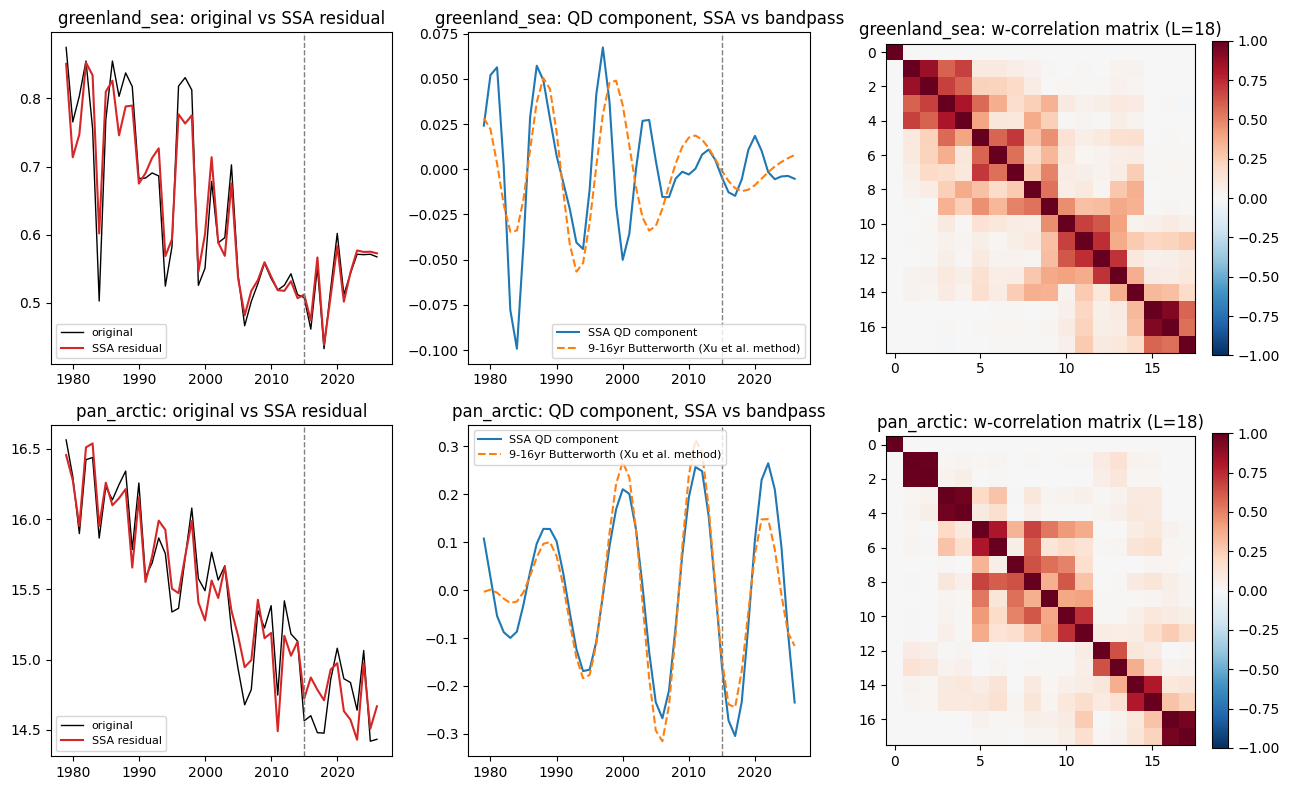

In [9]:
# NOTE: no sharex here — column 2 is an imshow (matrix-index x-axis,
# 0..L-1), while columns 0-1 plot calendar years. Sharing x across the
# row would lock the year-axis line plots to the imshow's tiny 0..L
# range, making them appear empty.
fig, axes = plt.subplots(len(series_dict), 3, figsize=(13, 4 * len(series_dict)))
if len(series_dict) == 1:
    axes = axes[np.newaxis, :]

for row, (name, series) in enumerate(series_dict.items()):
    years = series.index.values
    y = series.values
    res = ssa_results[name]
    bpf = bandpass_results[name]

    ax = axes[row, 0]
    ax.plot(years, y, color='k', lw=1, label='original')
    ax.plot(years, y - res['RC_QD'], color='tab:red', lw=1.5, label='SSA residual')
    ax.axvline(SPLIT_YEAR, color='grey', ls='--', lw=1)
    ax.set_title(f'{name}: original vs SSA residual')
    ax.legend(fontsize=8)

    ax = axes[row, 1]
    ax.plot(years, res['RC_QD'], color='tab:blue', label='SSA QD component')
    ax.plot(years, bpf['QD_bandpass'], color='tab:orange', ls='--',
            label='9-16yr Butterworth (Xu et al. method)')
    ax.axvline(SPLIT_YEAR, color='grey', ls='--', lw=1)
    ax.set_title(f'{name}: QD component, SSA vs bandpass')
    ax.legend(fontsize=8)

    ax = axes[row, 2]
    im = ax.imshow(res['Wcorr'], cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_title(f'{name}: w-correlation matrix (L={L_DEFAULT})')
    plt.colorbar(im, ax=ax, fraction=0.046)

fig.tight_layout()
fig.savefig(OUTPUT_DIR + 'figure_s06_QD_SSA_extraction.png', dpi=FIG_DPI)
plt.show()


## Section 9 - Methodology writeup

In [ ]:
def write_methodology():
    lines = [
        "# Figure S6 - Quasi-Decadal Cycle Extraction (SSA) and Residual Regime-Shift Test",
        "",
        "## Purpose",
        "Tests whether the post-2015 breakpoint signal in Greenland Sea / pan-Arctic",
        "annual maximum SIE survives removal of the quasi-decadal (~8-10yr) internal",
        "variability mode, addressing whether the regime shift is distinct from Xu et",
        "al. (2026)'s TPQD-driven quasi-decadal oscillation.",
        "",
        "## Data",
        f"OSISAF annual maximum SIE, {START_YEAR}-present, via figure_01's cached",
        "annual_max_sie_dates.csv (no reprocessing from raw OSISAF files here).",
        "",
        "## Method",
        f"1. SSA (window length L={L_DEFAULT}) via SVD of the trajectory matrix.",
        "2. Monte Carlo SSA (Allen & Smith, 1996) against an AR(1) red-noise null,",
        f"   {MC_N_SURROGATES} surrogates, {int(MC_CONFIDENCE*100)}% confidence.",
        f"3. QD eigen-triple pair identified: significant + dominant period in",
        f"   {QD_PERIOD_RANGE} yr.",
        "4. Cross-checked against Xu et al. (2026)'s own fixed 9-16yr Butterworth",
        "   bandpass extraction method.",
        f"5. Breakpoint statistics (SPLIT_YEAR={SPLIT_YEAR}, Yue-Wang MK, bootstrap",
        f"   n={N_BOOTSTRAP}) applied to original, SSA-residual, and bandpass-residual.",
        f"6. Window-length robustness sweep: L in {L_SENSITIVITY}.",
        "",
        "## Status",
        "DRAFT - not yet run against real data. Implementation is pure numpy/scipy,",
        "no new SSA-package dependency added.",
    ]
    with open(METHODS_DIR + 'figure_s06_methodology.md', 'w') as f:
        f.write('\n'.join(lines))
    logger.info(f"Methodology written: {METHODS_DIR}figure_s06_methodology.md")

write_methodology()
